In [7]:
# Add relevant Jupyter notebook extensions 

In [8]:
# You can double-check your Python path like this...
import sys  
print(sys.path)

['/opt/anaconda3/lib/python313.zip', '/opt/anaconda3/lib/python3.13', '/opt/anaconda3/lib/python3.13/lib-dynload', '', '/Users/ahmed/.local/lib/python3.13/site-packages', '/opt/anaconda3/lib/python3.13/site-packages', '/opt/anaconda3/lib/python3.13/site-packages/aeosa']


# Simulate closed-loop
Load the provided mission, run the depth controller, and plot the resulting trajectory.

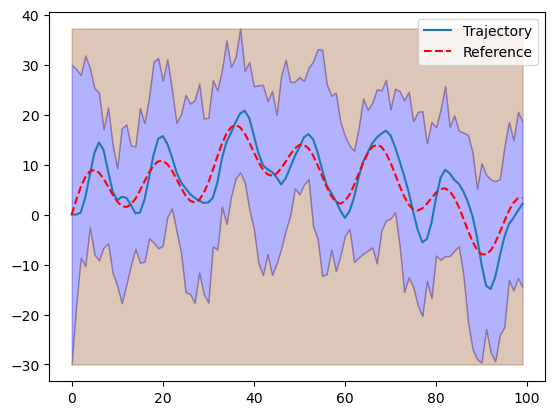

In [9]:
from uuv_mission.control import PDcontrol
from uuv_mission.dynamic import ClosedLoop, Mission, Submarine

sub = Submarine()
mission = Mission.from_csv("data/mission.csv")
controller = PDcontrol()
closed_loop = ClosedLoop(sub, controller)

trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)

### Controller tracking error

In [ ]:
import numpy as np

depth_error = mission.reference - trajectory.position[:, 1]
print(f"MAE: {np.mean(np.abs(depth_error)):.2f}")
print(f"RMSE: {np.sqrt(np.mean(depth_error**2)):.2f}")